# IAU Projekt - fáza 3
**Marek Kujan Privrel** a **Martin Benko** (rozdelenie práce 50:50)  
Cvičenie: Utorok 16:00 s Ing. Laurou Krajčovičovou  

In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.metrics import accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

In [137]:
RANDOM_SEED = 1

In [138]:
train_df = pd.read_csv("train_preprocessed.csv")
test_df = pd.read_csv("test_preprocessed.csv")

X_train, y_train = train_df.drop(columns=["failure"]), train_df["failure"]
X_test, y_test = test_df.drop(columns=["failure"]), test_df["failure"]

## 3.1 ID3 - Jednoduchý klasifikátor na základe závislosti v dátach

Kód nižšie definuje našu vlastnú implementáciu ID3 algoritmu, ktorý buduje rozhodovací strom na základe entropie, resp. information gain potencionálnych podstromov. 
- **trieda Node** definuje uzol v rozhodovacom strome. Má vlastné metódy, väčšina z nich sú len pomocné, no tá hlavná je metóda **live_and_make_children()** ktorá rekurzívne buduje ďalšie uzly stromu podľa zvoleného najvýhodnejšieho atribútu.  
- **trieda ID3_Classifier** potom len prepája logiku jednotlivých uzlov tak, aby sa dali použiť pre vybudovanie stromu (metóda **train()**), prehľadávanie stromu pre predikovanie výsledku `failure` pomocou metódy **predict()**, alebo hromadné otestovanie výsledkov nad dátami cez funkciu **test()**.

In [139]:
def define_ranges(unique_values) -> dict: # definuje dictionary, kde key je poradie triedy a value je dictionary s hranicami intervalu tejto kategórie
    unique_values = pd.Series(unique_values).sort_values(ascending=True)
    cuts = (unique_values + unique_values.shift(1))/2
    cuts = cuts.to_list()[1:]
    
    output = {}
    for n in range(len(cuts)+1):
        output[n] = {
            "low_boundry": -np.inf if n == 0 else cuts[n-1],
            "high_boundry": np.inf if n == len(cuts) else cuts[n],
            "child_node": "-"
        }

    return output

def calc_entropy(data: pd.DataFrame): # vypočíta entropiu pre data
        p = data["failure"].value_counts(normalize=True)
        return abs((p * np.log2(p)).sum())

In [140]:
class Node():
    def __init__(self, data: pd.DataFrame, attribute_types: dict, depth: int, max_depth: int):
        self.data = data
        self.attribute_types = attribute_types
        self.depth = depth
        self.max_depth = max_depth
        self.final = False
        self.entropy = calc_entropy(self.data)
        self.children = {}   # 0: {"low_boundry": , "high_boundry": , "child_node": Node()}
        self.attribute = None
        self.prediction = None


    def pick_best_attribute(self) -> tuple: # vypočíta information gain pre každý z ostávajúcich atribútov a vyberie ten najlepší pre tento uzol
        cols = self.data.columns.to_list()
        cols.pop(cols.index("failure"))

        best_ig = 0
        best_attr = None
        best_split_point = None

        for col in cols:
            ig, split_point = self.try_attribute(col)
            if ig > best_ig:
                best_ig = ig
                best_attr = col
                best_split_point = split_point

        return best_attr, best_split_point

    def live_and_make_children(self):  # rekurzívne budovanie stromu 
        self.prediction = round(self.data["failure"].mean())

        if self.depth == self.max_depth:
            self.final = True
            return

        if self.entropy == 0:
            self.final = True
            return

        self.attribute, split_point = self.pick_best_attribute()
        if self.attribute == None:
            self.final = True
            return

        if split_point == None:   # kategorický atribút
            self.children = define_ranges(self.data[self.attribute].unique())

        else:                     # numerický atribút
            self.children = {
                0: { "low_boundry": -np.inf, "high_boundry": split_point, "child_node": "-"},
                1: { "low_boundry": split_point, "high_boundry": np.inf, "child_node": "-"}
            }
            
        for val in self.children.values():
            column = self.data[self.attribute]
            
            child_data = self.data.loc[(column > val["low_boundry"]) & (column <= val["high_boundry"])]

            if split_point is None:     # odstraňujem len kategorické atribúty, numerické ešte môžu poslúžiť
                child_data = child_data.drop(columns=self.attribute)

            val["child_node"] = Node(child_data, self.attribute_types, self.depth+1, self.max_depth)
            val["child_node"].live_and_make_children()

            
    """def try_attribute(self, attribute: str) -> tuple:      # toto je pôvodná implementácia algoritmu, no bola príliš pomalá pre gridsearch a preto je teraz odkomentovaná

        if self.attribute_types[attribute] == "categorical":      # Kategorické atribúty == nunique pod 100 hodnôt spracujeme podľa ID3 algoritmu

            categories = pd.DataFrame(self.data[attribute].value_counts(normalize=True))

            for category in categories.index.to_list():
                categories.loc[category, "entropy"] = calc_entropy(self.data.loc[self.data[attribute] == category])

            categories["product"] = categories.entropy * categories.proportion
            
            weighted_entropy = abs(np.sum(categories["product"]))
            info_gain = self.entropy - weighted_entropy
            return info_gain, None

            
        
        # Spojité atribúty - hľadáme najlepší split point, podľa ktorého bude info_gain najlepší

        temp = self.data[[attribute, "failure"]].sort_values(by=attribute)
        temp["middle"] = (temp[attribute] + temp[attribute].shift(1)) / 2

        thresholds = temp.loc[temp[attribute] != temp[attribute].shift(1), "middle"].dropna()

        thresholds = pd.DataFrame({"threshold": thresholds})

        if thresholds.empty:
            return 0, None

        thresholds["percentage_left"] = thresholds["threshold"].apply(lambda t: (temp[attribute] <= t).mean())
        thresholds["percentage_right"] = 1 - thresholds["percentage_left"]

        thresholds["entropy_left"] = thresholds["threshold"].apply(lambda t: calc_entropy(temp[temp[attribute] <= t]))
        thresholds["entropy_right"] = thresholds["threshold"].apply(lambda t: calc_entropy(temp[temp[attribute] > t]))

        thresholds["weighted_entropy"] = (thresholds["percentage_left"] * thresholds["entropy_left"] + thresholds["percentage_right"] * thresholds["entropy_right"])

        best_index = thresholds["weighted_entropy"].idxmin()
        info_gain = self.entropy - thresholds.at[best_index, "weighted_entropy"]
        best_split_point = thresholds.at[best_index, "threshold"]

        return info_gain, best_split_point"""

    def try_attribute(self, attribute):     # zvektorizovaná verzia odkomentovanej funkcie vyššie  (pomohol Claude)
        if self.attribute_types[attribute] == "categorical":
            g = self.data.groupby(attribute)["failure"].agg(["mean", "size"])
            p1 = g["mean"].to_numpy()
            with np.errstate(divide="ignore", invalid="ignore"):
                e = -(np.where(p1 > 0, p1 * np.log2(p1), 0) +
                    np.where(p1 < 1, (1 - p1) * np.log2(1 - p1), 0))
            weighted_entropy = (e * g["size"].to_numpy()).sum() / len(self.data)
            return self.entropy - weighted_entropy, None

        x = self.data[attribute].to_numpy()
        y = self.data["failure"].to_numpy()

        order = np.argsort(x, kind="stable")
        x = x[order]
        y = y[order]
        n = len(y)

        # výber potencionálnych splitpointov
        change = np.nonzero(x[1:] != x[:-1])[0]      # index posledného prvku ľavej časti
        if change.size == 0:
            return 0, None

        cum_pos = np.cumsum(y)
        total_pos = cum_pos[-1]

        n_left = change + 1
        n_right = n - n_left
        pos_left = cum_pos[change]
        pos_right = total_pos - pos_left

        # lokálna verzia funkcie calc_entropy()
        def ent(pos, cnt):   
            p1 = pos / cnt
            p0 = 1 - p1
            with np.errstate(divide="ignore", invalid="ignore"):
                e = -(np.where(p1 > 0, p1 * np.log2(p1), 0) +
                    np.where(p0 > 0, p0 * np.log2(p0), 0))
            return e

        weighted = (n_left * ent(pos_left, n_left) + n_right * ent(pos_right, n_right)) / n

        best = np.argmin(weighted)
        split_point = (x[change[best]] + x[change[best] + 1]) / 2
        return self.entropy - weighted[best], split_point
    
    def find_range(self, value):
        for key, val in self.children.items():
            if value <= val["high_boundry"]:
                if value > val["low_boundry"]:
                    return key
        raise Exception("Funkcia 'find_range()' nenašla rozsah :( pravdepodobne kvôli hodnote NaN")
    


In [141]:
class ID3_Classifier():
    def __init__(self, max_depth: int = 100):
        self.root = None
        self.max_depth = max_depth

    def train(self, data: pd.DataFrame):
        attribute_types = {}
        for attr in data.columns.to_list():
            attribute_types[attr] = "categorical" if data[attr].nunique() < 100 else "numeric"
        
        self.root = Node(data, attribute_types, 1, self.max_depth)
        self.root.live_and_make_children()

    def fit(self, X, y):
        self.train(pd.concat([X,y], axis=1))

    def single_predict(self, test_vector: pd.Series):
        crossroad = self.root
        while not crossroad.final:
            index = crossroad.find_range(test_vector[crossroad.attribute])
            crossroad = crossroad.children[index]["child_node"]

        return crossroad.prediction

    def predict(self, data: pd.DataFrame):
        predictions = []
        for row_num in range(len(data)):
            row = data.loc[row_num]
            predictions.append(self.single_predict(row))
            
        return np.array(predictions)  



Bez akéhohoľvek pruningu algoritmus na našich testovacích dátach `test_df` dosiahol hodnoty `Accuracy = 79.65 %`, `Precision: 20.58 %` a `Recall: 22.16 %`.   
Otestovali sme ho aj na `train_df`, aby sme si overili či bol strom správne vytvorený a teraz vieme že bol, lebo mal všetky 3 metriky na 100 %, čo je overfit jak delo. To sme očakávali a dalším krokom bol pre-pruning, teda testovanie ako obmedzenie maximálnej hĺbky stromu ovplyvní výsledné metriky. Očakávame zhoršenie výsledkov pre `train_df` a snáď výrazné zlepšenie metrík pre `test_df`. Priamo úmerne by sme sa mali zlepšiť aj časy budovania stromu.

### 3.1C Efekt Pre-pruningu

In [142]:
def get_metrics_from_runs(train_df, test_df, y_test, depth_limits: list = range (2, 30, 2)):
    runs = pd.DataFrame({"accuracy": [], "precision": [], "recall": []})

    for depth in depth_limits:
        id3 = ID3_Classifier(depth)
        id3.train(train_df)

        y_pred = id3.predict(test_df)
        runs.loc[depth] = [
            accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred, zero_division=0),
            recall_score(y_test, y_pred)
        ]
        # print(f"Depth = {key}")
    
    return runs
    

In [143]:
train_plot_df = get_metrics_from_runs(train_df, X_train, y_train)
test_plot_df = get_metrics_from_runs(train_df, X_test, y_test)

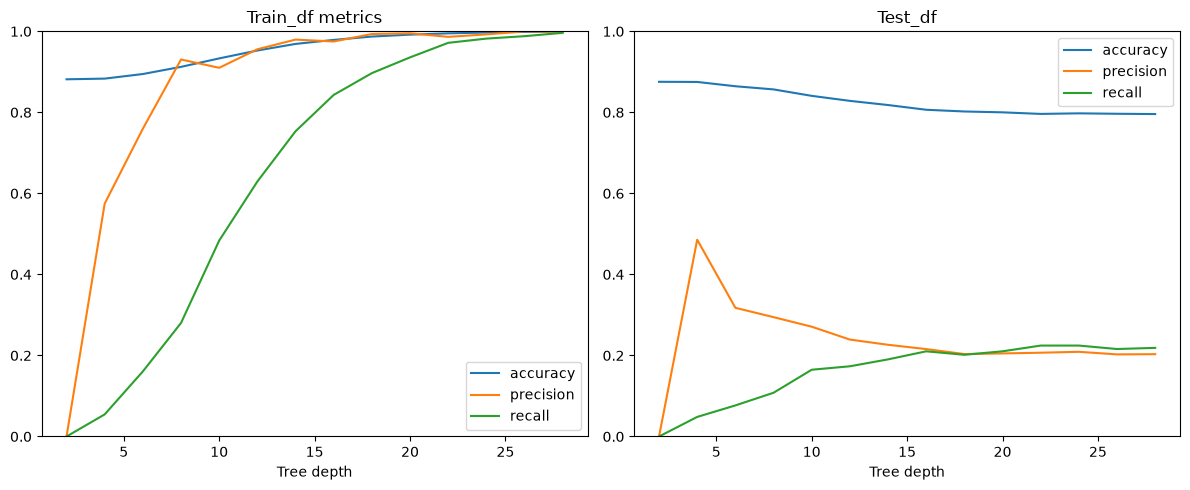

In [144]:

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, plot_df) in zip(axs, [("Train_df metrics", train_plot_df), ("Test_df", test_plot_df)]):
    ax.plot(plot_df)
    ax.legend(plot_df.columns)
    ax.set_xlabel("Tree depth")
    ax.set_ylim(0, 1)
    ax.set_title(title)

fig.tight_layout()
plt.show()


V grafe vyššie je vidno efekt pre-pruningu na validačné metriky nášho algoritmu. Podľa ľavého grafu môžme povedať, že algoritmus už pri `maximálnej hĺbke > 10` začína mať výrazný overfit, čo vidno podľa metrík konvergujúcich k 1.   
Graf napravo ukazuje klesajúci trend `accuracy`, ktorá pri najmenšom možnom strome dosiahla 87%. To je ale samozrejme neželaný stav, ktorý už Marek popísal na začiatku sekcie 3.2 a vyplýva z nevyváženosti našich trénovacích dát. Jednoducho keď model natipuje všetky hodnoty na `0`, v 87% prípadov sa trafí, ale *precision* a *recall* budú nulové.
Ako najlepší variant preto berieme ID3 s maximálnou hĺbkou 10.

### Post-pruning
Post-pruning je technika, ktorá by nám možno priniesla o málo lepšie výsledky, no podľa slabého účinku pre-pruningu sme sa rozhodli skôr zamerať na kvalitu a vyváženie dát, než aby sme implementovali ďalší spôsob korekcie overfitu.

### Vyváženie dát

In [145]:
minority = train_df[train_df['failure'] == 1]
majority = train_df[train_df['failure'] == 0]

majority_down = majority.sample(n=len(minority), random_state=RANDOM_SEED)

train_balanced = (pd.concat([minority, majority_down]).sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True))

X_train_balanced, y_train_balanced = train_balanced.drop(columns=["failure"]), train_balanced["failure"]


In [146]:
train_plot_df = get_metrics_from_runs(train_balanced, X_train_balanced, y_train_balanced, range(2, 12, 1))
test_plot_df = get_metrics_from_runs(train_balanced, X_test, y_test, range(2, 12, 1))

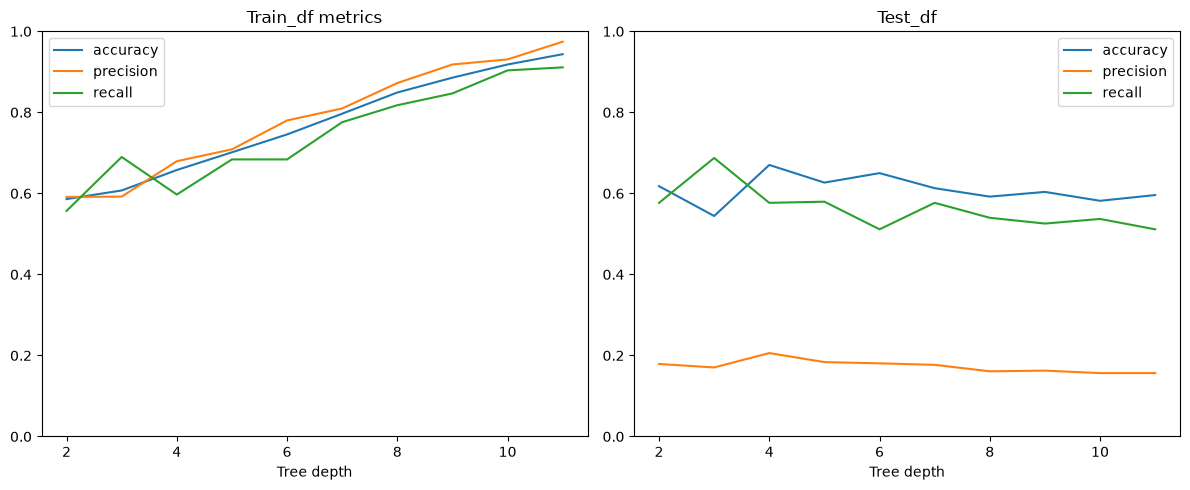

In [147]:

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, plot_df) in zip(axs, [("Train_df metrics", train_plot_df), ("Test_df", test_plot_df)]):
    ax.plot(plot_df)
    ax.legend(plot_df.columns)
    ax.set_xlabel("Tree depth")
    ax.set_ylim(0, 1)
    ax.set_title(title)

fig.tight_layout()
plt.show()


Keď odstránime náhodne časť záznamov z train_df tak, aby boli value_counts v train_df podľa failure rovnaké, síce tým stratíme asi 4/5 záznamov, no zníži to výrazne zaujatosť ID3 algoritmu voči atribútu `failure`. Výsledkom je síce nižšia `accuracy`, no `recall` už dosahuje rozumné hodnoty.   
Model overfituje až neskôr pri hlbších stromoch.
Podľa týchto výsledkov by sme mali ďalej pracovať s modelom o hĺbke 4.

## 3.2 Trénovanie a vyhodnotenie klasifikátorov strojového učenia

In [148]:
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("podiel failure v train:", round(y_train.mean(), 3), "v test:", round(y_test.mean(), 3))

X_train: (11303, 10) X_test: (2826, 10)
podiel failure v train: 0.118 v test: 0.125


Naše dátá sú nevyvážené. Dáta s poruchou sa vyskytujú iba v približne 12% pripadoch. Pokiaľ by náš model pre všetky prípady predikoval, že nedošlo k poruchu, dosiahol by presnosť 88%, ale ani raz by nenašiel skutočnú poruchu. Preto pri vyhodnocovaní budeme sledovať popri **accuracy** hlavne **precision** a **recall** pre triedu `failure = 1`:
- **recall** hovorí, koľko skutočných porúch model odhalil.
- **precision** ukazuje, z koľkých predikovaných porúch boli naozajstné poruchy.

In [149]:
def evaluate(name, model): # funkcia pre vyhodnotenie modelu 
    rows = []
    for split, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        y_pred = model.predict(X)
        rows.append({
            "model": name,
            "mnozina": split,
            "accuracy": accuracy_score(y, y_pred),
            "precision": precision_score(y, y_pred, zero_division=0),
            "recall": recall_score(y, y_pred),
        })
    return pd.DataFrame(rows)

results = []

### Stromový algoritmus - DecisionTreeClassifier
Vybrali sme stromový algoritmus DecisionTreeClassifier, ktorý používa algoritmus CART. Čiže to vyzerá ako dobrá voľba na porovanie s ID3 algoritmom.

Skúsime strom natrenovať s predvolenými parametrami.

In [150]:
from sklearn.tree import DecisionTreeClassifier

tree_default = DecisionTreeClassifier(random_state=RANDOM_SEED).fit(X_train, y_train)
print("hlbka stromu:", tree_default.get_depth(), "pocet listov:", tree_default.get_n_leaves())
results.append(evaluate("DecisionTree (default)", tree_default))
results[-1].round(3)

hlbka stromu: 28 pocet listov: 1466


,model,mnozina,accuracy,precision,recall
0,DecisionTree (default),train,1.000,1.000,1.000
1,DecisionTree (default),test,0.795,0.203,0.222


Náš strom sa rozrástol do hĺbky 28 a vyprodukoval až 1466 listov. Ked sa pozrieme na metriky, tak je jasne vidno, že storm sa dokonale naučil trénovacie dáta, ale na testovacej množine už to vôbec nevyzeralo dobre: precision 0,203 a recall 0,222. Jednoznačne sa teda jedna o overfitting. 

Aby sme mali lepší model na porovnanie, tak sa pokusime znižiť overfitting nastavenim maximalnej hĺbky stromu na 5. Kedže sú naše dáta nevyvážené, tak pre porovnanie natrénujeme strom aj s parametrom `class_weight="balanced"`, ktorý dáva väčšiu váhu menšínovej triede.

In [151]:
tree_d5 = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_SEED).fit(X_train, y_train)
results.append(evaluate("DecisionTree (max_depth=5)", tree_d5))

tree_bal = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_SEED).fit(X_train, y_train)
results.append(evaluate("DecisionTree (max_depth=5, balanced)", tree_bal))

pd.concat(results[-2:]).round(3)

,model,mnozina,accuracy,precision,recall
0,DecisionTree (max_depth=5),train,0.884,0.580,0.084
1,DecisionTree (max_depth=5),test,0.873,0.413,0.054
0,"DecisionTree (max_depth=5, balanced)",train,0.689,0.220,0.641
1,"DecisionTree (max_depth=5, balanced)",test,0.665,0.205,0.588


Strom s maximalnou hĺbkou 5 už neoverfituje no recall má len 0.054. Zachytí približne 5% poruch. Ked ho porovnáme s modelom kde sme nastavili `class_weight="balanced"` tak tu už recall stúpol na 0.588 čiže náš model zachytí približne 59% porúch. Accuracy klesla na 0.665, pretože model teraz častejšie označí aj záznam bez poruchy ako poruchu a precision je 0.205.

### Nestromový algoritmus - Logistická regresia
Ako nestromový algoritmus sme si vybrali **logistickú regresiu**.

Rovnako ako pri strome skúsime verziu bez vyváženia tried a s `class_weight="balanced"`.

In [152]:
logreg = LogisticRegression().fit(X_train, y_train)
results.append(evaluate("LogisticRegression", logreg))

logreg_bal = LogisticRegression(class_weight="balanced").fit(X_train, y_train)
results.append(evaluate("LogisticRegression (balanced)", logreg_bal))

pd.concat(results[-2:]).round(3)

,model,mnozina,accuracy,precision,recall
0,LogisticRegression,train,0.884,0.729,0.026
1,LogisticRegression,test,0.879,0.867,0.037
0,LogisticRegression (balanced),train,0.664,0.212,0.676
1,LogisticRegression (balanced),test,0.655,0.214,0.659


Logistická regresia sa správa rovnako ako strom. Bez vyváženia tried predikuje poruchu len výnimočne: precision je síce 0.867, ale recall iba 0.037, takže zachytí iba zlomok porúch.  S `class_weight="balanced"` dosahuje recall **0.659** pri precision 0.214, čo je o niečo lepšie ako Decission tree s `class_weight="balanced"`.

Keď porovname metriky na trénovacej a testovacej množine, tak sú takmer rovnake, čiže náš model neoverfituje.

Ďalej porovnávame už len vyvážené verzie modelov.

### Matice zámen
Pre vyzualizáciu počtu zachytených a nezachytených porúch si na testovacej množine vykreslíme maticu zámen pre Decission tree a Logistickú regresiu.

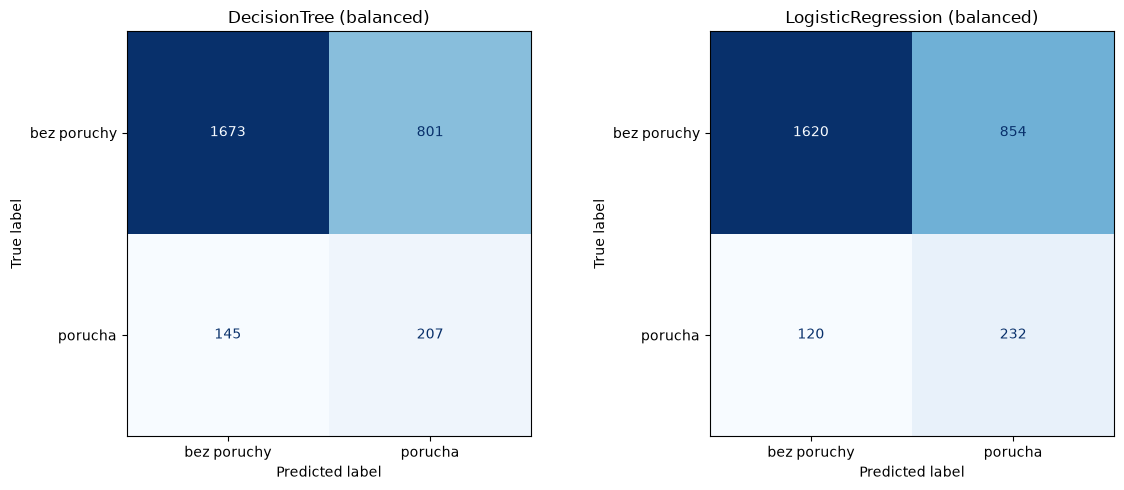

In [153]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axs, [("DecisionTree (balanced)", tree_bal), ("LogisticRegression (balanced)", logreg_bal)]):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["bez poruchy", "porucha"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
fig.tight_layout()
plt.show()

Z 352 porúch zachití Decission tree 207 a Logistická regresia 232. Oba modeli majú celkom veľa false positive. Modely majú precision iba okolo 0.2, čiže poruchy sa oddeľujú od bežnej prevádzky len slabo.

### Vizualizácia natrénovaných pravidiel

Vizualizujeme si natrenované pravidlá DecissionTreeClassifier pomocout `plot_tree`. Pre čitateľnosť zobrazíme len prvé 2 úrovne stromu.

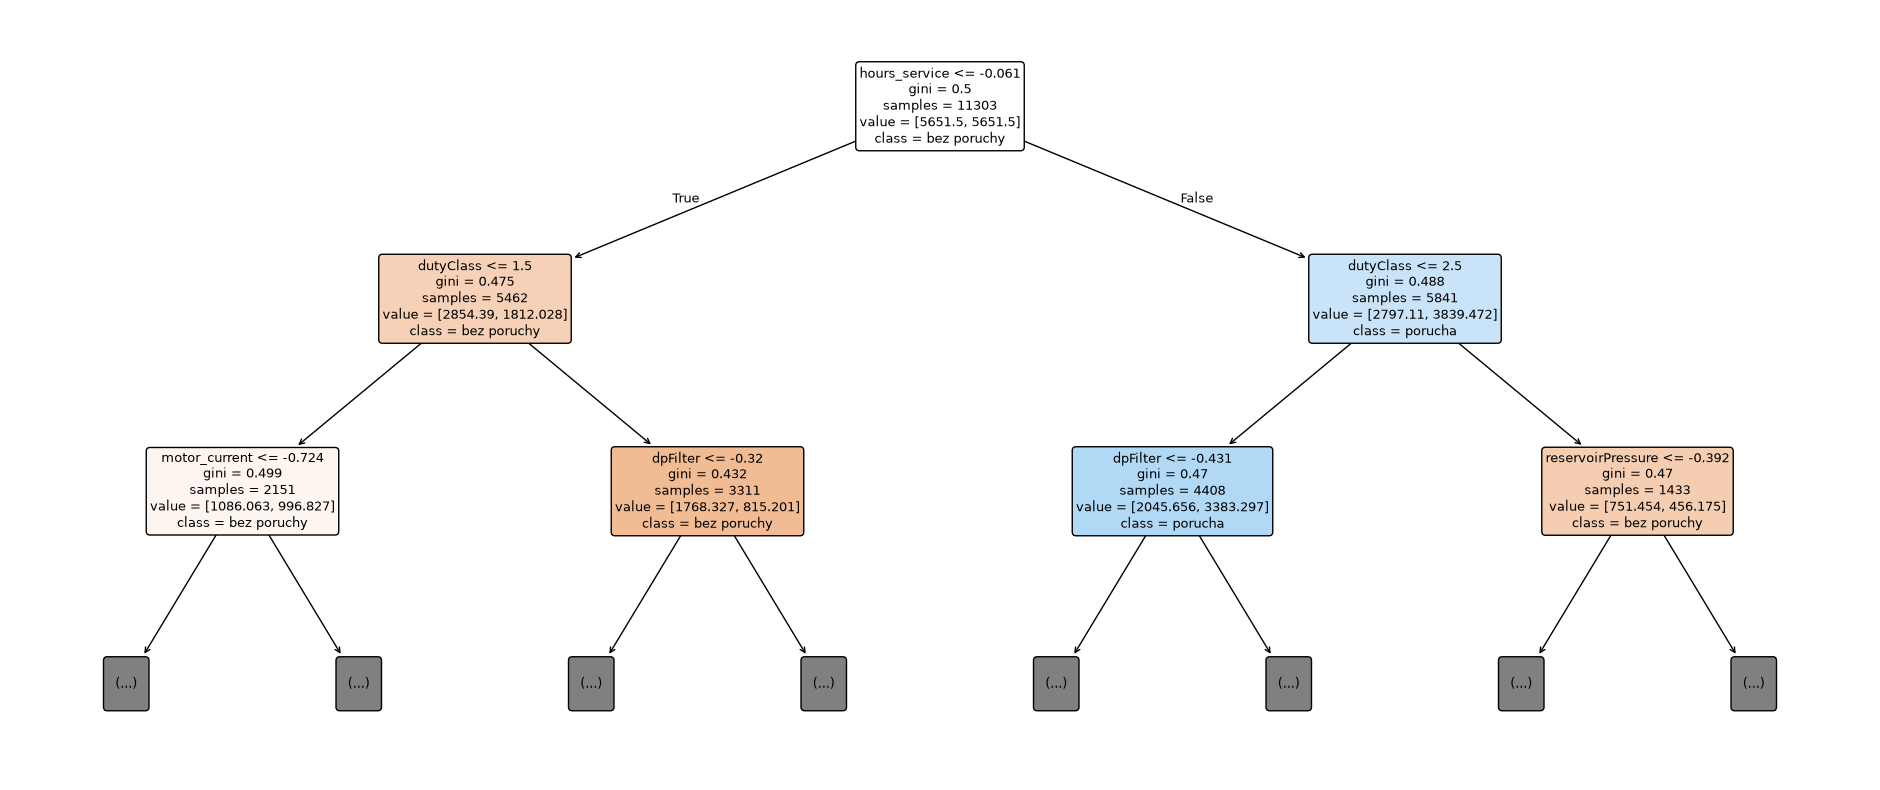

In [154]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(tree_bal, feature_names=X_train.columns, class_names=["bez poruchy", "porucha"], filled=True, rounded=True, max_depth=2, fontsize=9, ax=ax)
plt.show()

Na začiatku sa strom delí podľa `hours_service` čo dáva aj zmysel keďže jednotky s večším počtom odpracovaných hodín môžu mať väčšiu pravdepodobnosť poruchy. Celkom zaujmavé je že vyšia dutyClass vedie skôr k triede bez poruchy. 

Pri logistickej regresii si vieme vizualizovať koeficienty modelu. Kladný koeficient zvyšuje pravdepodobnosť poruchy, záporný ju zase znižuje.

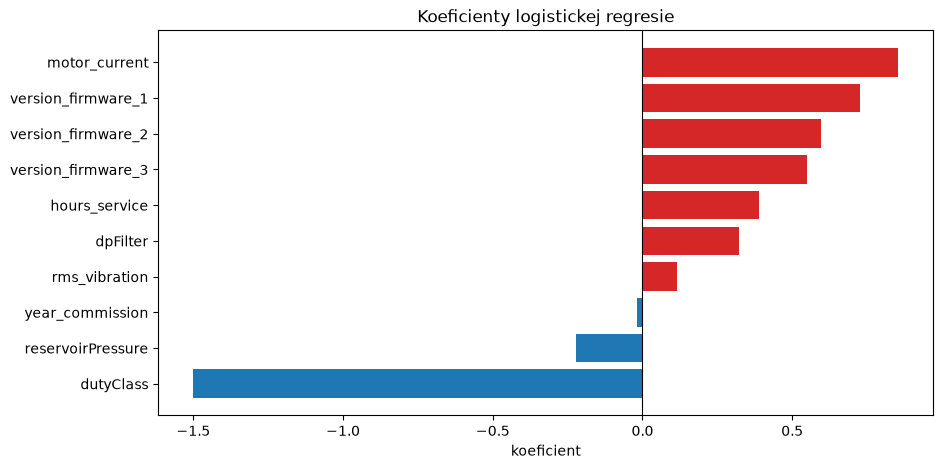

In [155]:
coefs = pd.Series(logreg_bal.coef_[0], index=X_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(coefs.index, coefs.values, color=["tab:red" if c > 0 else "tab:blue" for c in coefs.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Koeficienty logistickej regresie")
ax.set_xlabel("koeficient")
plt.show()

### Porovnanie modelov a porovnanie s ID3

Náš ID3 klasifikátor v porovnaní s ostatnými testovanými modelmi ani nevyniká, ani nie je najhorší. V metrikách `precision` aj `recall` víťazí Logistická regresia, no podľa týchto metrík zatiaľ ťažko určiť celkového víťaza.

In [156]:
id3 = ID3_Classifier(max_depth=10)
id3.train(train_df)
results.append(evaluate("ID3 (max_depth=10)", id3))

comparison = pd.concat(results, ignore_index=True)
(comparison
    .pivot(index="model", columns="mnozina", values=["accuracy", "precision", "recall"])
    .reindex(index=comparison["model"].unique())
    .reindex(columns=["train", "test"], level=1) 
    .round(3))

accuracy        precision        recall  \
mnozina                                 train   test     train   test  train   
model                                                                          
DecisionTree (default)                  1.000  0.795     1.000  0.203  1.000   
DecisionTree (max_depth=5)              0.884  0.873     0.580  0.413  0.084   
DecisionTree (max_depth=5, balanced)    0.689  0.665     0.220  0.205  0.641   
LogisticRegression                      0.884  0.879     0.729  0.867  0.026   
LogisticRegression (balanced)           0.664  0.655     0.212  0.214  0.676   
ID3 (max_depth=10)                      0.933  0.841     0.910  0.271  0.484   

                                             
mnozina                                test  
model                                        
DecisionTree (default)                0.222  
DecisionTree (max_depth=5)            0.054  
DecisionTree (max_depth=5, balanced)  0.588  
LogisticRegression                    0.037  
LogisticRegression (balanced)         0.659  
ID3 (max_depth=10)                    0.165

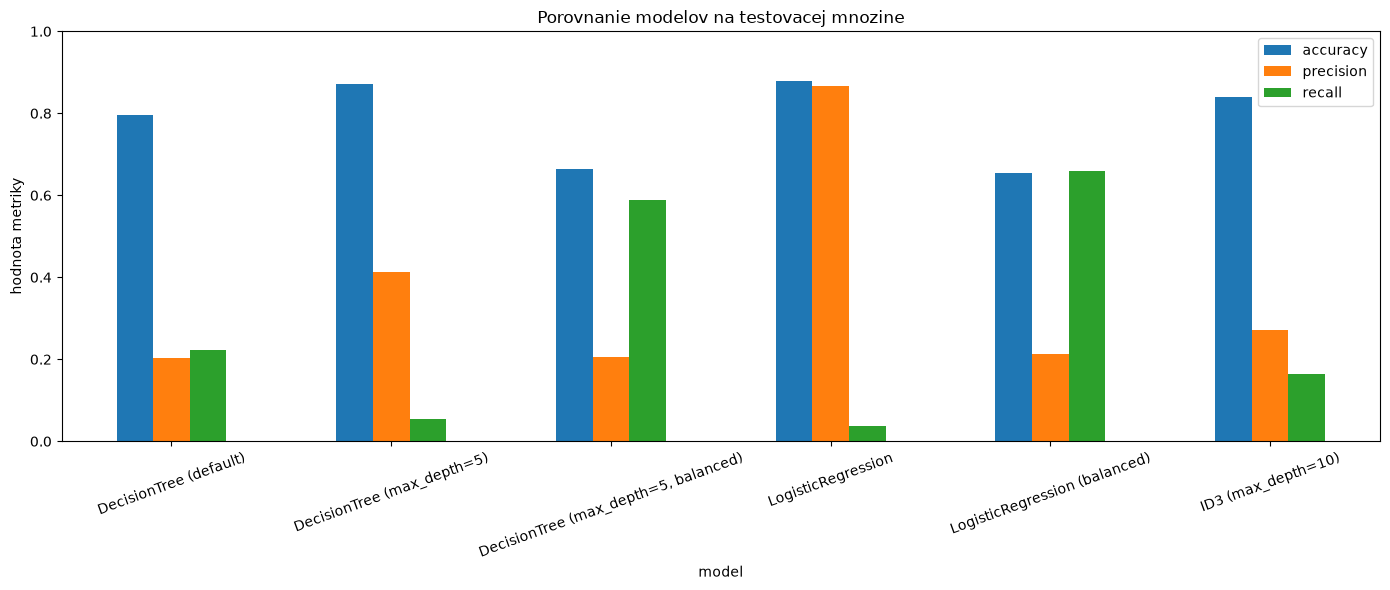

In [157]:
test_results = comparison[comparison["mnozina"] == "test"].set_index("model")[["accuracy", "precision", "recall"]]

test_results.plot(kind="bar", figsize=(14, 6), rot=20)
plt.title("Porovnanie modelov na testovacej mnozine")
plt.ylabel("hodnota metriky")
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

### Zhrnutie 3.2
- **Stromový model (`DecisionTreeClassifier`)** bez obmedzenia hlbky overfitoval, Po obmedzení hĺbky a vyvážení tried dosahuje na testovacej množine recall 0.588 a precision 0.205 bez overfitu.
- **Nestromový model (`LogisticRegression`)** model s vyvažením tired je o niečo lepši od DecissionTreeClassifier s vyvážením tried. Na testovacej množine dosahuje recall 0.659 a precision 0.214. Train a test metriky sú takmer rovnaké, čiže model neoverfituje.
- **Porovnanie s ID3:** Model logistickej regresie prekonal náš ID3 klasifikátor, a tak už ďalej s ID3 klasifikátorom nebudeme pracovať.

### Úprava data preprocessingu z fázy 2

Nadpadlo nám ešte skontrolovať či sme nahradením chýbajúcich hodnôt pomocou KNN imputeru neprišli o informáciu o tom že tam hodnota chýbala. 

In [158]:

readings = pd.read_csv("readings.csv", delimiter="\t").drop_duplicates()
readings["id_unit"] = readings["id_unit"].str.replace("U", "").astype(int)
units = pd.read_csv("units.csv")
df = readings.merge(units[["id_unit", "hours_service"]], on="id_unit", how="inner")
df["temperature_oil"] = df["temperature_oil"].replace(-999, np.nan)
df["motor_current"] = df["motor_current"].replace(99, np.nan)

missing_cols = [col for col in df.columns if df[col].isna().any()]
pd.DataFrame({
    "pocet chybajucich": df[missing_cols].isna().sum(),
    "failure ked chyba atribúť": [df.loc[df[col].isna(), "failure"].mean() for col in missing_cols],
    "failure ked je nechýba atribúť": [df.loc[df[col].notna(), "failure"].mean() for col in missing_cols],
}).round(3)

,pocet chybajucich,failure ked chyba atribúť,failure ked je nechýba atribúť
motor_current,16,0.062,0.120
dpFilter,539,0.553,0.102
temperature_oil,38,0.211,0.119
rms_vibration,554,0.534,0.103
humidityIntake,681,0.104,0.120
hours_service,728,0.109,0.120


Z tabuľky vyššie je vidieť, že keď chýba `dpFilter` alebo `rms_vibration`, ide až v viac ako 50% prípadov o poruchu, a pri nameranich hodnotách len v 10 %. KNN imputer vo fáze 2 tieto hodnoty doplnil podľa susedov a túto informáciu sme tak stratili.

Znova teda vytvoríme dáta s tým že KNN imputeru pridáme `add_indicator=True`. Imputer potom pre každý atribút s chýbajúcimi hodnotami pridá nový stĺpec s informáciou či hodnota chýbala.

In [159]:
import category_encoders as ce
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, PowerTransformer
from sklearn.impute import KNNImputer

readings_df = pd.read_csv("readings.csv", delimiter="\t", parse_dates=["ts_cycle"], date_format="mixed")
readings_df["id_unit"] = readings_df["id_unit"].str.replace("U", "").astype(int)
readings_df = readings_df.drop_duplicates().drop(columns=["ts_cycle"])

units_df = pd.read_csv("units.csv", delimiter=",")
units_df["dutyClass"] = units_df["dutyClass"].str.strip()
units_df = units_df.replace({
    "1": "light", "L": "light",
    "N": "medium", "2": "medium", "normal": "medium", "med": "medium",
    "3": "heavy", "H": "heavy"
})

gateways_df = pd.read_csv("gateways.csv", delimiter=";")
gateways_df = gateways_df.dropna(subset="id_unit")
gateways_df["id_unit"] = gateways_df["id_unit"].astype(int)

main_df = (
    readings_df
    .merge(units_df[["id_unit", "year_commission", "dutyClass", "hours_service"]], on="id_unit", how="inner", validate="many_to_one")
    .merge(gateways_df[["id_unit", "version_firmware"]], on="id_unit", how="inner", validate="many_to_one")
)
for col, code in {"temperature_oil": -999, "motor_current": 99}.items():
    main_df[col] = main_df[col].replace(code, np.nan)

X_raw = main_df.drop(columns=["failure", "id_unit"])
y_raw = main_df["failure"]
X_raw_train, X_raw_test, y_raw_train, y_raw_test = sklearn.model_selection.train_test_split(X_raw, y_raw, test_size=0.2, random_state=RANDOM_SEED)

CATEGORICAL_COLS = ["dutyClass", "version_firmware"]
NUMERIC_COLS = [col for col in X_raw.columns if col not in CATEGORICAL_COLS]
mapping = [{"col": "dutyClass", "mapping": {"light": 1, "medium": 2, "heavy": 3}}]

x = Pipeline([
    ("ordinal", ce.OrdinalEncoder(cols=["dutyClass"], mapping=mapping)),
    ("onehot", ce.OneHotEncoder(cols=["version_firmware"])),
    ("scale", ColumnTransformer([("robust", RobustScaler(), NUMERIC_COLS)], remainder="passthrough", verbose_feature_names_out=False)),
    ("impute", KNNImputer(n_neighbors=5, add_indicator=True)),
    ("power", ColumnTransformer([("yeo_johnson", PowerTransformer(method="yeo-johnson"), NUMERIC_COLS)], remainder="passthrough", verbose_feature_names_out=False)),
]).set_output(transform="pandas").fit_transform(X_raw_train)
print("pocet atributov:", x.shape[1])
print("nove stlpce:", [col for col in x.columns if col.startswith("missingindicator_")])

pocet atributov: 20
nove stlpce: ['missingindicator_motor_current', 'missingindicator_dpFilter', 'missingindicator_temperature_oil', 'missingindicator_rms_vibration', 'missingindicator_humidityIntake', 'missingindicator_hours_service']


Výber atribútov úplne rovnako ako vo fáze 2, len sme odstránili podmienku, že keď je zvolený jeden atribúť version_firmware, tak musia byť zvolené všetky version_firmware.

In [160]:
from sklearn.feature_selection import mutual_info_classif, RFE, SelectFromModel
from sklearn.ensemble import RandomForestClassifier

mic_out = pd.Series(mutual_info_classif(x, y_raw_train, random_state=0), index=x.columns)
rfe_out = pd.Series(RFE(LogisticRegression(class_weight="balanced"), n_features_to_select=1, step=1).fit(x, y_raw_train).ranking_, index=x.columns)
rfc_out = pd.Series(RandomForestClassifier(random_state=0).fit(x, y_raw_train).feature_importances_, index=x.columns)
sfm_lr_out = pd.Series(SelectFromModel(estimator=LogisticRegression()).fit(x, y_raw_train).estimator_.coef_[0], index=x.columns).abs()

results_v2 = pd.DataFrame({
    "Mutual Info": mic_out.rank(ascending=False, method="min").astype(int),
    "RFE+LogisticReg": rfe_out,
    "Random Forest": rfc_out.rank(ascending=False, method="min").astype(int),
    "SFM+LogisticReg": sfm_lr_out.rank(ascending=False, method="min").astype(int),
})
results_v2["sum points"] = results_v2.sum(axis=1)
results_v2["final order"] = results_v2["sum points"].rank(method="min").astype(int)

def select_features(max_rank):  # prvych max_rank atributov podla finalneho poradia (max_rank = maximalny pocet atributov)
    return results_v2.sort_values("final order", kind="stable").index[:max_rank].tolist()

MAX_RANK = 9
SELECTED_FEATURES_V2 = select_features(MAX_RANK)

results_v2["vybrany teraz"] = results_v2.index.isin(SELECTED_FEATURES_V2)
results_v2["vybrany vo faze 2"] = results_v2.index.isin(X_train.columns)
results_v2.sort_values("final order")

,Mutual Info,RFE+LogisticReg,Random Forest,SFM+LogisticReg,sum points,final order,vybrany teraz,vybrany vo faze 2
missingindicator_dpFilter,1,1,10,1,13,1,True,False
motor_current,6,4,1,4,15,2,True,True
missingindicator_rms_vibration,2,2,11,2,17,3,True,False
dutyClass,4,3,13,3,23,4,True,True
hours_service,3,9,5,7,24,5,True,True
dpFilter,8,10,2,6,26,6,True,True
Flowmeter,10,12,7,9,38,7,True,False
reservoirPressure,17,11,4,8,40,8,True,True
year_commission,5,13,12,11,41,9,True,True
version_firmware_2,7,6,14,15,42,10,False,True


Indikátory `missingindicator_dpFilter` a `missingindicator_rms_vibration` sa dostali na 1. a 3. miesto čiže vyzera, že nesú dôležitú informáciu tak ako sme predpokladali.

Čize zmeny oproti fáze 2 vyzerajú nasledovne:
 - Pribudli `missingindicator_dpFilter` a `missingindicator_rms_vibration`
 - vypadol `rms_vibration`
 - a vypadli všetky `version_firmware` kedže najlepší z nich už klesol na 10. miesto.

Spolu máme teda 9 atribútov namiesto 10.

Vytvoríme pipline už aj s výberom atribútov. Funkcia `prepare_data(features)` zo surových dát pripraví trénovacie a testovacie dáta s atribútmi zo zoznamu `features`. Zoznam môžeme získať cez `select_features(max_rank)`, alebo zadať vlastný:
- `prepare_data(select_features(5))` - prvých 5 atribútov podľa finálneho poradia (`max_rank` je maximálny počet atribútov),
- `prepare_data(["motor_current", "dutyClass", "missingindicator_dpFilter"])` - vlastný zoznam atribútov.

In [161]:
def prepare_data(features):  # zo surovych dat pripravi trenovacie a testovacie data s atributmi zo zoznamu features
    unknown = [col for col in features if col not in x.columns]
    if unknown:
        raise ValueError(f"nezname atributy: {unknown}, dostupne su: {list(x.columns)}")

    preprocessing = Pipeline([
        ("ordinal", ce.OrdinalEncoder(cols=["dutyClass"], mapping=mapping)),
        ("onehot", ce.OneHotEncoder(cols=["version_firmware"])),
        ("scale", ColumnTransformer([("robust", RobustScaler(), NUMERIC_COLS)], remainder="passthrough", verbose_feature_names_out=False)),
        ("impute", KNNImputer(n_neighbors=5, add_indicator=True)),
        ("power", ColumnTransformer([("yeo_johnson", PowerTransformer(method="yeo-johnson"), NUMERIC_COLS)], remainder="passthrough", verbose_feature_names_out=False)),
        ("select", ColumnTransformer([("selected", "passthrough", list(features))], remainder="drop", verbose_feature_names_out=False)),
    ]).set_output(transform="pandas")

    X_train_prepared = preprocessing.fit_transform(X_raw_train)
    X_test_prepared = preprocessing.transform(X_raw_test)
    return X_train_prepared, X_test_prepared, preprocessing

X_train_v2, X_test_v2, preprocessing_v2 = prepare_data(SELECTED_FEATURES_V2)
print("X_train_v2:", X_train_v2.shape, "X_test_v2:", X_test_v2.shape)

X_train_v2: (11303, 9) X_test_v2: (2826, 9)


### 3.2 na nových dátach
Natrenujeme pre porovnanie rovnaké modely ako v 3.2

In [162]:
def evaluate_v2(name, model):
    rows = []
    for split, X, y in [("train", X_train_v2, y_raw_train), ("test", X_test_v2, y_raw_test)]:
        y_pred = model.predict(X)
        rows.append({
            "model": name,
            "mnozina": split,
            "accuracy": accuracy_score(y, y_pred),
            "precision": precision_score(y, y_pred, zero_division=0),
            "recall": recall_score(y, y_pred),
        })
    return pd.DataFrame(rows)

models_v2 = {
    "DecisionTree (default)": DecisionTreeClassifier(random_state=RANDOM_SEED),
    "DecisionTree (max_depth=5)": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_SEED),
    "DecisionTree (max_depth=5, balanced)": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_SEED),
    "LogisticRegression": LogisticRegression(),
    "LogisticRegression (balanced)": LogisticRegression(class_weight="balanced")
}
comparison_v2 = pd.concat([evaluate_v2(name, model.fit(X_train_v2, y_raw_train)) for name, model in models_v2.items()], ignore_index=True)

(comparison_v2.pivot(index="model", columns="mnozina", values=["accuracy", "precision", "recall"])
              .reindex(index=comparison_v2["model"].unique())
              .reindex(columns=["train", "test"], level=1)
              .round(3))

accuracy        precision        recall  \
mnozina                                 train   test     train   test  train   
model                                                                          
DecisionTree (default)                  1.000  0.812     1.000  0.264  1.000   
DecisionTree (max_depth=5)              0.896  0.887     0.661  0.629  0.250   
DecisionTree (max_depth=5, balanced)    0.822  0.812     0.339  0.336  0.528   
LogisticRegression                      0.896  0.897     0.694  0.796  0.224   
LogisticRegression (balanced)           0.753  0.752     0.277  0.291  0.674   

                                             
mnozina                                test  
model                                        
DecisionTree (default)                0.284  
DecisionTree (max_depth=5)            0.222  
DecisionTree (max_depth=5, balanced)  0.517  
LogisticRegression                    0.233  
LogisticRegression (balanced)         0.693

Porovnanie dát z fázy 2 a z nových dát, ktoré obsahujú indikátory chýbajúcich hodnôt:

In [163]:
metrics = ["accuracy", "precision", "recall"]
old_test = comparison[comparison["mnozina"] == "test"].set_index("model")[metrics]
new_test = comparison_v2[comparison_v2["mnozina"] == "test"].set_index("model")[metrics].reindex(old_test.index)
pd.concat({"faza 2": old_test, "s indikatorom": new_test, "rozdiel": new_test - old_test}, axis=1).round(3)

faza 2                  s indikatorom  \
                                     accuracy precision recall      accuracy   
model                                                                          
DecisionTree (default)                  0.795     0.203  0.222         0.812   
DecisionTree (max_depth=5)              0.873     0.413  0.054         0.887   
DecisionTree (max_depth=5, balanced)    0.665     0.205  0.588         0.812   
LogisticRegression                      0.879     0.867  0.037         0.897   
LogisticRegression (balanced)           0.655     0.214  0.659         0.752   
ID3 (max_depth=10)                      0.841     0.271  0.165           NaN   

                                                       rozdiel            \
                                     precision recall accuracy precision   
model                                                                      
DecisionTree (default)                   0.264  0.284    0.017     0.061   
DecisionTree (max_depth=5)               0.629  0.222    0.014     0.216   
DecisionTree (max_depth=5, balanced)     0.336  0.517    0.147     0.130   
LogisticRegression                       0.796  0.233    0.018    -0.071   
LogisticRegression (balanced)            0.291  0.693    0.096     0.078   
ID3 (max_depth=10)                         NaN    NaN      NaN       NaN   

                                             
                                     recall  
model                                        
DecisionTree (default)                0.063  
DecisionTree (max_depth=5)            0.168  
DecisionTree (max_depth=5, balanced) -0.071  
LogisticRegression                    0.196  
LogisticRegression (balanced)         0.034  
ID3 (max_depth=10)                      NaN

Pridanie indikátora chýbajúcich hodnôt do predspracovania teda modelom pomohlo.

### Logistická regresia podľa počtu atribútov

Skúsime natrénovať logistickú regresiu s rôznym počtom atribútov od 1 po 15. Pre porovnanie to spravíme s vyvážením tried aj bez.

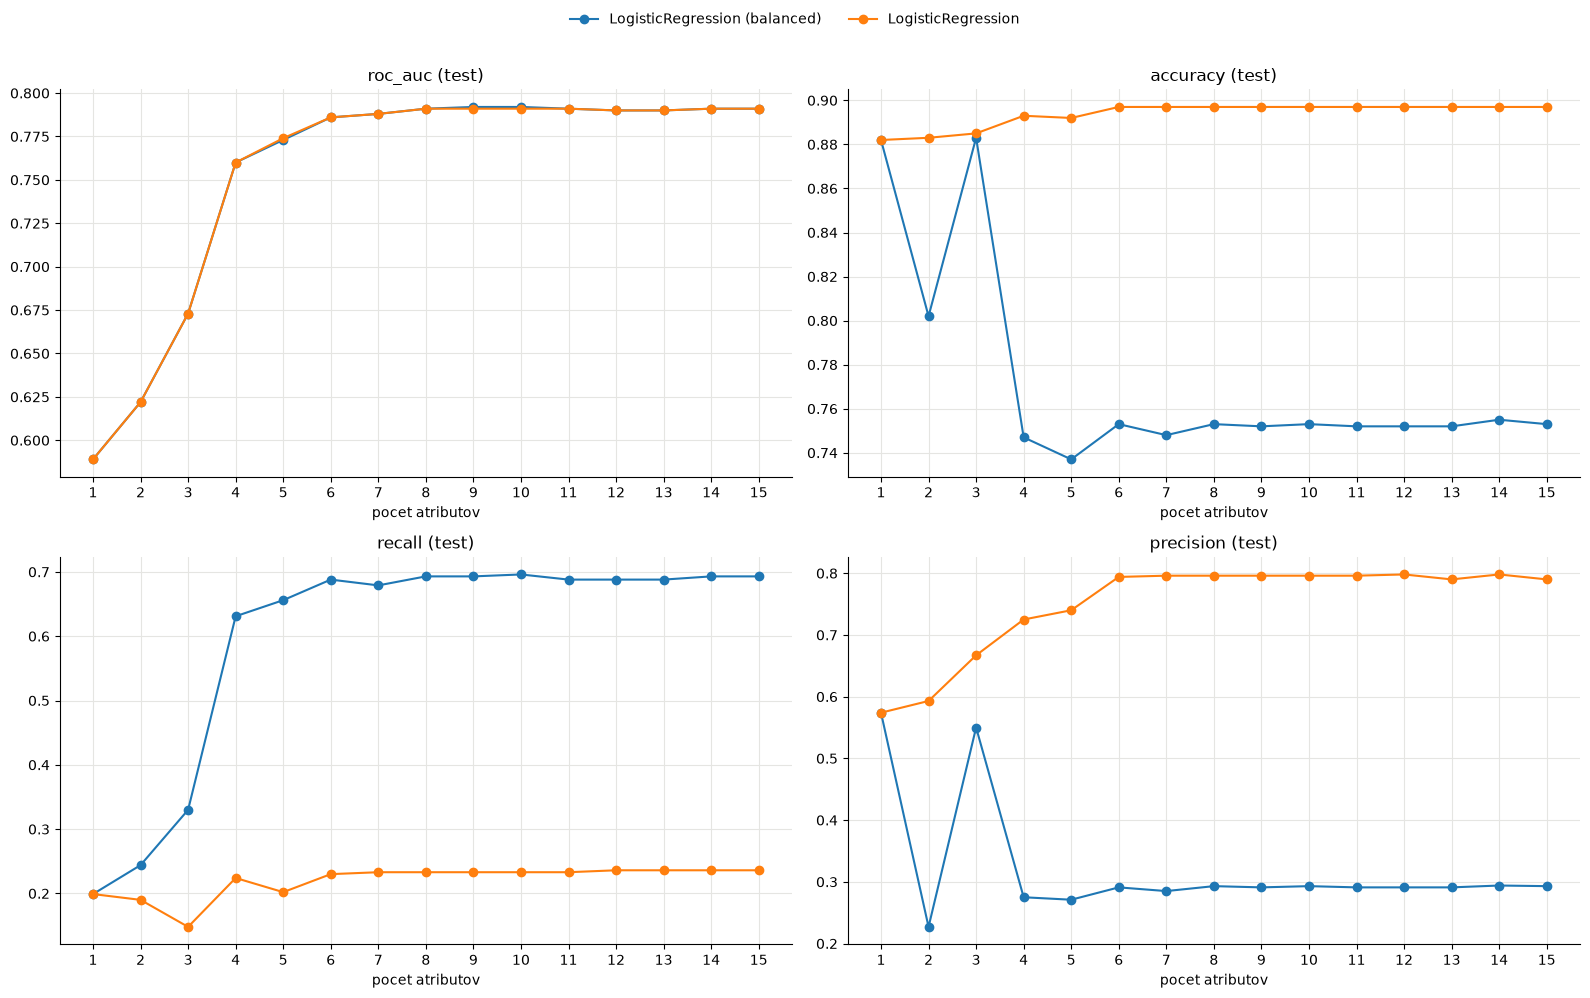

In [20]:
from sklearn.metrics import roc_auc_score

lr_models = {
    "LogisticRegression (balanced)": LogisticRegression(class_weight="balanced"),
    "LogisticRegression": LogisticRegression(),
}
rows = []
for k in range(1, 16):
    X_tr, X_te, _ = prepare_data(select_features(k))
    for model_name, model in lr_models.items():
        model.fit(X_tr, y_raw_train)
        y_pred = model.predict(X_te)
        rows.append({
            "model": model_name,
            "pocet atributov": k,
            "roc_auc": round(roc_auc_score(y_raw_test, model.predict_proba(X_te)[:, 1]), 3),
            "accuracy": round(accuracy_score(y_raw_test, y_pred), 3),
            "recall": round(recall_score(y_raw_test, y_pred), 3),
            "precision": round(precision_score(y_raw_test, y_pred, zero_division=0), 3),
        })
lr_k = pd.DataFrame(rows)

fig, axs = plt.subplots(2, 2, figsize=(16, 10))
for ax, metric in zip(axs.ravel(), ["roc_auc", "accuracy", "recall", "precision"]):
    for model_name, group in lr_k.groupby("model", sort=False):
        ax.plot(group["pocet atributov"], group[metric], marker="o", label=model_name)
    ax.set_title(f"{metric} (test)")
    ax.set_xlabel("pocet atributov")
    ax.set_xticks(range(1, 16))
    ax.grid(color="#e5e5e2", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

In [21]:
(lr_k.pivot(index="pocet atributov", columns="model", values=["roc_auc", "accuracy", "recall", "precision"])
     .reindex(columns=list(lr_models), level=1))

roc_auc                     \
model           LogisticRegression (balanced) LogisticRegression   
pocet atributov                                                    
1                                       0.589              0.589   
2                                       0.622              0.622   
3                                       0.673              0.673   
4                                       0.760              0.760   
5                                       0.773              0.774   
6                                       0.786              0.786   
7                                       0.788              0.788   
8                                       0.791              0.791   
9                                       0.792              0.791   
10                                      0.792              0.791   
11                                      0.791              0.791   
12                                      0.790              0.790   
13                                      0.790              0.790   
14                                      0.791              0.791   
15                                      0.791              0.791   

                                     accuracy                     \
model           LogisticRegression (balanced) LogisticRegression   
pocet atributov                                                    
1                                       0.882              0.882   
2                                       0.802              0.883   
3                                       0.883              0.885   
4                                       0.747              0.893   
5                                       0.737              0.892   
6                                       0.753              0.897   
7                                       0.748              0.897   
8                                       0.753              0.897   
9                                       0.752              0.897   
10                                      0.753              0.897   
11                                      0.752              0.897   
12                                      0.752              0.897   
13                                      0.752              0.897   
14                                      0.755              0.897   
15                                      0.753              0.897   

                                       recall                     \
model           LogisticRegression (balanced) LogisticRegression   
pocet atributov                                                    
1                                       0.199              0.199   
2                                       0.244              0.190   
3                                       0.330              0.148   
4                                       0.631              0.224   
5                                       0.656              0.202   
6                                       0.688              0.230   
7                                       0.679              0.233   
8                                       0.693              0.233   
9                                       0.693              0.233   
10                                      0.696              0.233   
11                                      0.688              0.233   
12                                      0.688              0.236   
13                                      0.688              0.236   
14                                      0.693              0.236   
15                                      0.693              0.236   

                                    precision                     
model           LogisticRegression (balanced) LogisticRegression  
pocet atributov                                                   
1                                       0.574              0.574  
2                                       0.227              0.593  
3                           

ROC AIC rastie približne do 8 atribútov a potom uz ostáva rovnaké. Ostatné vyhodnocovacie metriky sa tiež už po 8 atribútoch moc nemenia. 

## 3.3 Optimalizácia alias hyperparameter tuning

### Grid search - Logistická regresia

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html  
https://www.geeksforgeeks.org/machine-learning/how-to-optimize-logistic-regression-performance/#understanding-logistic-regression

Cross-validation robíme cez StratifiedKFold, pretože naše dáta sú nevyvážené a Stratified zachováva distribúcie tried rovnaké medzi foldmi.

**Accuracy** - máme nevyvážené dáta, takže nie je pre nás tým hlavným ukazovateľom  
**Precision** - koľko z predikovaných porúch boli naozaj poruchy - potrebná metrika  
**Recall** - koľko zo skutočných porúch náš model predpovedal - asi najdôležitejšie, lebo je lepšie predpovedať poruchu ak tam nie je, než ju neodhaliť keď tam je  
  
`GridSearchCV` počíta štatistiky pre scoring metriky. Najdôležitejšie sú:
- `mean_test_acc`, `mean_test_rec`,... - tie nám povedia aká bola priemerná hodnota metriky naprieč cross-validačnými behmi
- `diff_recall`, `diff_f1`, ... - pomáhajú nám **odhaliť overfit**, pretože čím vačší by bol rozdiel úspešnosti na trénovacích dátach oproti validačným, tým horší overfit
- `std_recall`, `std_precision`, ... - ak sú úspešnosti naprieč foldmi príliš rôzne (std väčsšie než 0.05), model je **nestabilný**


In [269]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

logreg = LogisticRegression(max_iter=2000, random_state=RANDOM_SEED) 

param_grid_lr = {
        "solver": ["saga"],
        "l1_ratio": [0, 0.2, 0.5, 0.8, 1],
        "C": [0.001, 0.01, 0.1, 1, 10, 100, np.inf],
        "class_weight": [None, "balanced"],
        # "max_iter": [500, 1000, 2000]
     }


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

scoring = {
    "acc": "accuracy",
    "prec": "precision",
    "rec": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "avg_pr": "average_precision",
}

gs = GridSearchCV(logreg, param_grid_lr, scoring=scoring, refit="avg_pr", cv=cv, return_train_score=True, n_jobs=-1)
gs.fit(X_train_v2, y_raw_train)

res = pd.DataFrame(gs.cv_results_)

rows = {}

for m in scoring.keys():
    # pri remíze (napr. recall = 1.0) rozhodne vyššia precision
    best_i = res.sort_values([f"mean_test_{m}", "mean_test_rec"], ascending=False).index[0]
    r = res.loc[best_i]

    rows[m] = {
        "params": {k.replace("solver", "solver"): v for k, v in r["params"].items()},
        # výkon na validačných foldoch
        "valid_accuracy":  r["mean_test_acc"],
        "valid_recall":    r["mean_test_rec"],
        "valid_precision": r["mean_test_prec"],
        "valid_f1":        r["mean_test_f1"],
        "valid_roc_auc":   r["mean_test_roc_auc"],
        "valid_avg_pr":    r["mean_test_avg_pr"],
        # overfit: train - test
        "diff_recall":     r["mean_train_rec"] - r["mean_test_rec"],
        "diff_f1":         r["mean_train_f1"] - r["mean_test_f1"],
        "diff_avg_pr":     r["mean_train_avg_pr"] - r["mean_test_avg_pr"],
        # stabilita: std cez foldy
        "std_recall":     r["std_test_rec"],
        "std_precision":  r["std_test_prec"],
        "std_accuracy":         r["std_test_acc"],
    }

compare_best = pd.DataFrame(rows)
compare_best.columns.name = "vybrané podla"

pd.set_option("display.max_colwidth", None)  # aby sa zobrazil celý obsah buniek
display(compare_best.T)



,params,valid_accuracy,valid_recall,valid_precision,valid_f1,valid_roc_auc,valid_avg_pr,diff_recall,diff_f1,diff_avg_pr,std_recall,std_precision,std_accuracy
vybrané podla,,,,,,,,,,,,,
acc,"{'C': 1, 'class_weight': None, 'l1_ratio': 0.8, 'solver': 'saga'}",0.896753,0.225709,0.698305,0.340772,0.785385,0.452007,-0.000372,-0.000731,0.001182,0.016958,0.031444,0.002341
prec,"{'C': 0.01, 'class_weight': None, 'l1_ratio': 0.8, 'solver': 'saga'}",0.882774,0.010459,0.95,0.020659,0.76627,0.410331,-0.001304,-0.002531,0.001669,0.003653,0.1,0.000297
rec,"{'C': 0.01, 'class_weight': 'balanced', 'l1_ratio': 0, 'solver': 'saga'}",0.729452,0.692065,0.259334,0.377175,0.780665,0.443122,-0.001296,0.000375,0.000368,0.022775,0.004659,0.00791
f1,"{'C': 0.1, 'class_weight': 'balanced', 'l1_ratio': 0.8, 'solver': 'saga'}",0.752544,0.674141,0.276443,0.392005,0.785291,0.45103,0.002803,0.001827,0.001119,0.026034,0.005423,0.005751
roc_auc,"{'C': 10, 'class_weight': None, 'l1_ratio': 0, 'solver': 'saga'}",0.896488,0.227204,0.691635,0.341691,0.785394,0.452078,0.000188,0.000293,0.001104,0.016426,0.029164,0.002194
avg_pr,"{'C': 0.1, 'class_weight': None, 'l1_ratio': 0, 'solver': 'saga'}",0.896222,0.188342,0.74474,0.300373,0.785149,0.452528,0.000934,0.00106,0.000913,0.011006,0.027877,0.001284


Tabuľka vyššie ukazuje zoznam najlepších hyperparametrov modelu Logistickej regresie, no kritérium pre nejlepšieho kandidáta sa medzi riadkami mení.   
Pre naše potešenie, takmer všetky modely sú relatívne stabilné, čo určuje štandardná odchylka recall, precision a accuracy.  
Rozdiely medzi úspešnosťou nad trénovacími vs. validačnými dátami sú malé, a teda modely nemajú ani overfit.  

Problém je ale že ani najlepšie hyperparametre nepriniesli výrazné zlepšenie a naša Logistická regresia asi underfituje.


In [244]:

logreg = LogisticRegression(max_iter=2000, random_state=RANDOM_SEED, C= 0.1, class_weight= "balanced", l1_ratio= 0.8, solver= "saga")
model = logreg.fit(X_train_v2, y_raw_train)

y_pred = model.predict(X_test_v2)

print(f"Accuracy: {accuracy_score(y_raw_test, y_pred)}")
print(f"Precision: {precision_score(y_raw_test, y_pred, zero_division=0)}")
print(f"Recall: {recall_score(y_raw_test, y_pred)}")

Accuracy: 0.7508846426043878
Precision: 0.2904761904761905
Recall: 0.6931818181818182


### Grid search - Decision Tree Classifier

Pri DecisionTreeClassifieri je narozdiel od Logistickej regresie problém vybrať zmysluplné atribúty do grid Search, pretože ich má strašne veľa.  
Stratégia je tu inak rovnaká, minimálny rozdiel medzi úspechom train vs. validačná množina, a minimálna štandardná odchylka.

In [276]:

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

tree = DecisionTreeClassifier(random_state=RANDOM_SEED)

param_dist_tree = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 8, 12, 20],
    "min_samples_split": [2, 10, 20, 50],
    "min_samples_leaf": [1, 5, 10, 20],
    "max_features": [None, "sqrt", 0.5, 0.7],
    "class_weight": [None, "balanced"],
    "ccp_alpha": [0, 0.0005, 0.001, 0.005],
}

scoring = {
    "acc": "accuracy",
    "prec": "precision",
    "rec": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "avg_pr": "average_precision",
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

REFIT = "rec"
rs = RandomizedSearchCV(tree, param_dist_tree, n_iter=100, scoring=scoring, refit=REFIT, cv=cv, return_train_score=True, random_state=RANDOM_SEED, n_jobs=-1)
rs.fit(X_train_v2, y_raw_train)

print("najlepšie parametre:", rs.best_params_)

res = pd.DataFrame(rs.cv_results_)
res["diff_acc"] = res["mean_train_acc"] - res["mean_test_acc"]
res["diff_recall"] = res["mean_train_rec"] - res["mean_test_rec"]
res["diff_f1"] = res["mean_train_f1"] - res["mean_test_f1"]

cols = [
    "mean_test_acc", "mean_test_prec", "mean_test_rec", "mean_test_f1",
    "diff_acc", "diff_recall", "diff_f1",
    "std_test_acc", "std_test_prec", "std_test_rec", "std_test_f1",
]
compare_best = res.sort_values(f"mean_test_{REFIT}", ascending=False).head(5)[cols]

pd.set_option("display.max_colwidth", None)
display(compare_best)

najlepšie parametre: {'min_samples_split': 20, 'min_samples_leaf': 20, 'max_features': 0.7, 'max_depth': 12, 'criterion': 'gini', 'class_weight': 'balanced', 'ccp_alpha': 0.0005}


,mean_test_acc,mean_test_prec,mean_test_rec,mean_test_f1,diff_acc,diff_recall,diff_f1,std_test_acc,std_test_prec,std_test_rec,std_test_f1
73,0.690525,0.224225,0.653966,0.333813,0.043617,0.176936,0.091604,0.015689,0.010743,0.014532,0.012586
14,0.688932,0.219525,0.627073,0.323966,0.009268,0.024079,0.015675,0.033312,0.015539,0.043585,0.010390
5,0.687518,0.216859,0.627025,0.322089,0.042200,0.187625,0.094567,0.013107,0.004816,0.026235,0.005158
30,0.726537,0.246855,0.624034,0.352255,0.024104,0.076463,0.048278,0.034955,0.020809,0.042543,0.016217
90,0.712025,0.232853,0.622542,0.338334,0.044367,0.197343,0.105620,0.019649,0.004370,0.050903,0.004724


Rozdiely `diff_...` vychádzajú príliš vysoké pre najlepší model (bol by to pravdepodobne overfit), preto vezmem radšej 2. najlepší model s hodnotami `diff` pod 0.05.  

In [284]:
res.loc[14, "params"]

{'min_samples_split': 2,
 'min_samples_leaf': 1,
 'max_features': 0.5,
 'max_depth': 5,
 'criterion': 'gini',
 'class_weight': 'balanced',
 'ccp_alpha': 0.0005}

In [280]:

tree = DecisionTreeClassifier(random_state=RANDOM_SEED, min_samples_split= 2, min_samples_leaf= 1, max_features= 0.5, max_depth= 5, criterion= 'gini', class_weight= 'balanced', ccp_alpha= 0.0005)
model = tree.fit(X_train_v2, y_raw_train)

y_pred = model.predict(X_test_v2)
print(f"Accuracy: {accuracy_score(y_raw_test, y_pred)}")
print(f"Precision: {precision_score(y_raw_test, y_pred, zero_division=0)}")
print(f"Recall: {recall_score(y_raw_test, y_pred)}")

Accuracy: 0.6440198159943383
Precision: 0.20959147424511546
Recall: 0.6704545454545454


Predikovanie na testovacích dátach bohužial dopadlo trochu inak, než sľuboval validačný priemer, ale aspoň to nie je overfit.

### 3.3B Ensamble

RandomForestClassifier je vlastne ensamble viacerých DecisionTreeClassifierov, takže môžme použiť hyperparametre z naposledy otestovaného DecisionTreeClassifieru a pozorovať, či ensamble bude mať lepšie výsledky než jediný strom.

In [287]:
from sklearn.ensemble import RandomForestClassifier


forest = RandomForestClassifier(n_estimators=300, random_state=RANDOM_SEED, min_samples_split= 2, min_samples_leaf= 1, max_features= 0.5, max_depth= 5, criterion= 'gini', class_weight= 'balanced', ccp_alpha= 0.0005)

model = forest.fit(X_train_v2, y_raw_train)

y_pred = model.predict(X_test_v2)
print(f"Accuracy: {accuracy_score(y_raw_test, y_pred)}")
print(f"Precision: {precision_score(y_raw_test, y_pred, zero_division=0)}")
print(f"Recall: {recall_score(y_raw_test, y_pred)}")



Accuracy: 0.7678697806086341
Precision: 0.29347826086956524
Recall: 0.6136363636363636


Porovnanie ukazuje, že máme lepšiu accuracy a precision, no recall klesol. Objektívne preto neviem povedať, či je výsledok RandomForestu lepší alebo horší.

## 3.4 Vyhodnotenie vplyvu zvolenej stratégie riešenia
Pre vyhodnotenie menime predspracovanie dát, a trenujeme vždy logistickú regresiu s vyvážením tried na všetkých atribútoch. Vyhodnocujeme na setovacej množine.

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import roc_auc_score

def evaluate_preprocessing(name, scaler=RobustScaler(), power=True, indicator=True):  # LR (balanced) na vsetkych atributoch, meni sa len predspracovanie
    steps = [
        ("ordinal", ce.OrdinalEncoder(cols=["dutyClass"], mapping=mapping)),
        ("onehot", ce.OneHotEncoder(cols=["version_firmware"])),
        ("scale", ColumnTransformer([("scaler", scaler, NUMERIC_COLS)], remainder="passthrough", verbose_feature_names_out=False)),
        ("impute", KNNImputer(n_neighbors=5, add_indicator=indicator)),
    ]
    if power:
        steps.append(("power", ColumnTransformer([("yeo_johnson", PowerTransformer(method="yeo-johnson"), NUMERIC_COLS)], remainder="passthrough", verbose_feature_names_out=False)))
    model = Pipeline(steps + [("model", LogisticRegression(class_weight="balanced"))]).set_output(transform="pandas")
    model.fit(X_raw_train, y_raw_train)
    y_pred = model.predict(X_raw_test)
    return {
        "predspracovanie": name,
        "roc_auc": roc_auc_score(y_raw_test, model.predict_proba(X_raw_test)[:, 1]),
        "accuracy": accuracy_score(y_raw_test, y_pred),
        "precision": precision_score(y_raw_test, y_pred),
        "recall": recall_score(y_raw_test, y_pred),
    }

Porovnáme predspracovanie z fázy 2 (KNN imputer bez indikátora) s upraveným predspracovaním (KNN imputer s `add_indicator=True`).

In [ ]:
pd.DataFrame([
    evaluate_preprocessing("KNN imputer (faza 2)", indicator=False),
    evaluate_preprocessing("KNN imputer + indikator chybania"),
]).set_index("predspracovanie").round(3)

,roc_auc,accuracy,precision,recall
predspracovanie,,,,
KNN imputer (faza 2),0.722,0.657,0.216,0.668
KNN imputer + indikator chybania,0.791,0.753,0.293,0.696


Indikátor chýbajúcich hodnôt celkom výrazne pomohol. Táto stratégia je teda pre náš dataset účinná.

Porovnáme rôzne scalery a predspracovanie s `PowerTransformer` (yeo-johnson) aj bez neho.

In [ ]:
pd.DataFrame([
    evaluate_preprocessing("RobustScaler + PowerTransformer (nase)"),
    evaluate_preprocessing("StandardScaler + PowerTransformer", scaler=StandardScaler()),
    evaluate_preprocessing("MinMaxScaler + PowerTransformer", scaler=MinMaxScaler()),
    evaluate_preprocessing("RobustScaler", power=False),
    evaluate_preprocessing("StandardScaler", scaler=StandardScaler(), power=False),
    evaluate_preprocessing("MinMaxScaler", scaler=MinMaxScaler(), power=False),
]).set_index("predspracovanie").round(3)

,roc_auc,accuracy,precision,recall
predspracovanie,,,,
RobustScaler + PowerTransformer (nase),0.791,0.753,0.293,0.696
StandardScaler + PowerTransformer,0.791,0.753,0.293,0.696
MinMaxScaler + PowerTransformer,0.791,0.754,0.294,0.696
RobustScaler,0.790,0.760,0.299,0.685
StandardScaler,0.790,0.762,0.299,0.682
MinMaxScaler,0.790,0.762,0.300,0.685


Výber scalera nemá na logistickú regresiu takmer žiadny vplyv. `PowerTransformer` mierne zvýši recall (0.696 oproti ~0.684), ale trochu zníži accuracy. Rozdiely sú veľmi malé.